# Align ScanImage traces to magnitude-bandit reward delivery

This notebook matches the random rsync pulse train recorded by ScanImage and pyControl, attaches the canonical `magnitude-bandit-analysis` trial variables, packages `dF` with the aligned session, and plots peri-reward ΔF/F.

**Reward timing convention:** rewarded trials enter pyControl's `choice` state immediately before the reward pulse train. `pulse_off_timer` marks pulse endings, so `choice` state entry is used as reward onset. The notebook verifies that the number of `choice` entries equals the number of trials with `reward_pulses > 0`.

In [80]:
from pathlib import Path
import importlib.util
import pickle
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
if ROOT.name == 'scripts':
    ROOT = ROOT.parent

# EDIT THESE: H5 and TSV must belong to the same acquisition.
H5_PATH = Path('/Volumes/behrens/meg/3x3_field_reward_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/striped_distortion_uncorrected/file_00389.h5')
# H5_PATH = Path('/Users/megyoung/Desktop/71rsuite2p/funcimg/file_00389.h5')
BEHAVIOR_TSV = Path('/Volumes/behrens/meg/3x3_field_reward_bandit/rawdata/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/behav/MY_71_R-2026-06-24-191859.tsv')
# BEHAVIOR_TSV = Path('/Users/megyoung/Desktop/71rsuite2p/behav/MY_71_R-2026-06-24-191859.tsv')
TRACE_DIR = Path('/Volumes/behrens/meg/3x3_field_reward_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/striped_distortion_uncorrected/suite2p/plane0/cellpose_suite2p_sliding_dff')  # contains dF.npy and dff.npy
# TRACE_DIR = Path('/Users/megyoung/Desktop/71rsuite2p/funcimg/suite2p/plane0/custom_green_mask_traces')  # contains dF.npy and dff.npy
OUTPUT_DIR = TRACE_DIR / 'behavior_alignment'
BEHAVIOR_PROJECT = Path('/Users/megyoung/magnitude-bandit-analysis')

ALIGN_SCRIPT = ROOT / 'scripts/align_scanimage_pycontrol.py'
EXTRACT_SCRIPT = ROOT / 'scripts/extract_traces_from_masks.py'
# The mini2p kernel may not contain h5py. Use base Anaconda for the H5 alignment in that case.
ALIGN_PYTHON = Path(sys.executable)
if importlib.util.find_spec('h5py') is None:
    ALIGN_PYTHON = Path('/Users/megyoung/anaconda3/bin/python')
    if not ALIGN_PYTHON.exists():
        raise ModuleNotFoundError(
            'h5py is absent from this notebook environment and base Anaconda was not found. '
            'Install h5py in the active environment before continuing.'
        )
print(f'Python used for HDF5 alignment: {ALIGN_PYTHON}')
ALIGNED_SESSION = OUTPUT_DIR / 'aligned_session.pkl'
FINAL_SESSION = OUTPUT_DIR / 'img_session_data.pkl'
QC_PLOT = OUTPUT_DIR / 'rsync_qc.png'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for path in (H5_PATH, BEHAVIOR_TSV, TRACE_DIR / 'F.npy', TRACE_DIR / 'F0.npy', TRACE_DIR / 'dff.npy'):
    if not path.exists():
        raise FileNotFoundError(f'Update the configuration above; not found: {path}')

Python used for HDF5 alignment: /Users/megyoung/anaconda3/envs/mini2p-preprocessing/bin/python


## 1. Align ScanImage and pyControl clocks

ScanImage frames: 14000
Rsync pulses: pyControl=365, ScanImage=365, matched=365
Aligned frames within rsync coverage: 13949/14000
Saved: /Volumes/behrens/meg/3x3_field_reward_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/striped_distortion_uncorrected/suite2p/plane0/cellpose_suite2p_sliding_dff/behavior_alignment/aligned_session.pkl



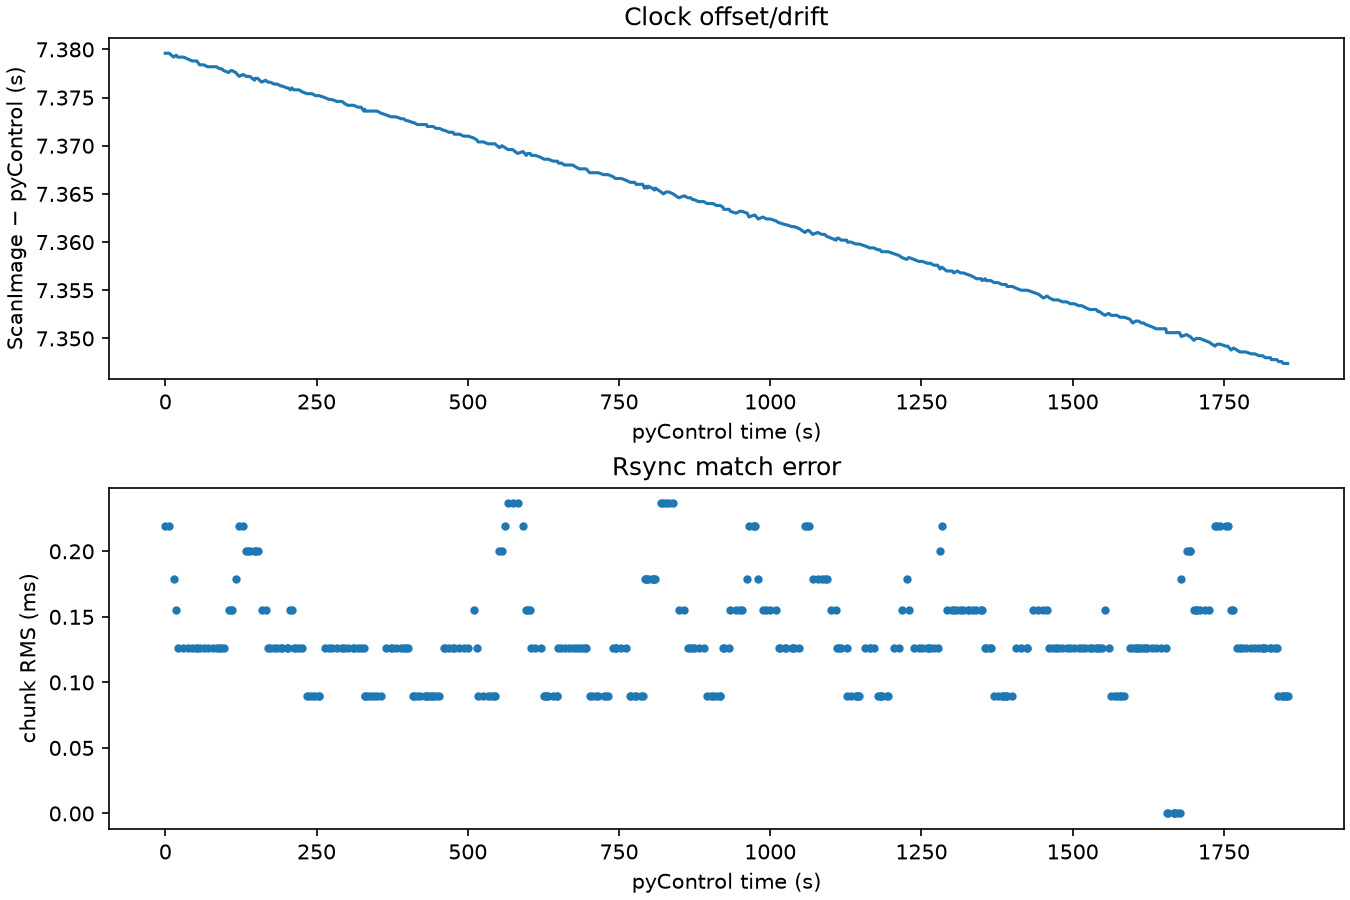

In [81]:
command = [
    str(ALIGN_PYTHON), str(ALIGN_SCRIPT),
    '--h5', str(H5_PATH),
    '--behavior-tsv', str(BEHAVIOR_TSV),
    '--output', str(ALIGNED_SESSION),
    '--behavior-project', str(BEHAVIOR_PROJECT),
    '--plot', str(QC_PLOT),
]
result = subprocess.run(command, check=False, text=True, capture_output=True)
if result.stdout:
    print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError(f'Alignment command failed with exit code {result.returncode}; see stderr above.')

with ALIGNED_SESSION.open('rb') as handle:
    session = pickle.load(handle)

display(QC_PLOT) if False else None
from IPython.display import display, Image
display(Image(filename=str(QC_PLOT)))

In [82]:
rsync = session['rsync']
print(f"Matched pulses: {len(rsync['matched_pycontrol_indices'])}")
print(f"Median chunk RMS: {np.median(rsync['chunk_rms_s']) * 1000:.3f} ms")
print(f"Maximum chunk RMS: {np.max(rsync['chunk_rms_s']) * 1000:.3f} ms")
print(f"Frames inside rsync coverage: {session['frame_valid'].sum()} / {len(session['frame_valid'])}")
print(f"Frame clock rate: {1 / np.nanmedian(np.diff(session['frame_times_scanimage_s'])):.4f} Hz")

Matched pulses: 365
Median chunk RMS: 0.126 ms
Maximum chunk RMS: 0.237 ms
Frames inside rsync coverage: 13949 / 14000
Frame clock rate: 7.5188 Hz


## 2. Load traces and package the aligned session

The existing outputs contain `F.npy`, `F0.npy`, and normalized `dff.npy`. This notebook reconstructs `dF = F - F0` in camera-intensity units, saves `dF.npy` for reuse, and uses `dff.npy` for the plots.

In [83]:
F = np.load(TRACE_DIR / 'F.npy', mmap_mode='r')
F0 = np.load(TRACE_DIR / 'F0.npy', mmap_mode='r')
dff = np.load(TRACE_DIR / 'dff.npy', mmap_mode='r')
frame_times = np.asarray(session['frame_times_pycontrol_s'])

if F.shape != dff.shape:
    raise ValueError(f'F shape {F.shape} != dff shape {dff.shape}')
if F0.ndim == 1 and F0.shape[0] == F.shape[0]:
    dF = (np.asarray(F, dtype=np.float32) - np.asarray(F0, dtype=np.float32)[:, None]).astype(np.float32)
elif F0.shape == F.shape:
    dF = (np.asarray(F, dtype=np.float32) - np.asarray(F0, dtype=np.float32)).astype(np.float32)
else:
    raise ValueError(
        f'Cannot broadcast F0 shape {F0.shape} against F shape {F.shape}; '
        'expected one F0 value per ROI or a framewise F0 array.'
    )
n_clock_frames = len(frame_times)
if dff.shape[1] == n_clock_frames + 1:
    # This acquisition's TIFF has one final frame after H5 clock recording stopped.
    # Keep frames 1..n_clock_frames and discard only the unclocked final frame.
    print(
        f'WARNING: traces contain one extra final frame ({dff.shape[1]} vs {n_clock_frames}). '
        'Dropping the last, unclocked trace frame.'
    )
    dF = dF[:, :n_clock_frames]
    dff = dff[:, :n_clock_frames]
    session['frame_reconciliation'] = {
        'original_trace_frames': int(F.shape[1]),
        'clock_frames': int(n_clock_frames),
        'action': 'dropped_final_unclocked_trace_frame',
    }
elif dff.shape[1] != n_clock_frames:
    raise ValueError(
        f'Traces have {dff.shape[1]} frames but the H5 FrameClock has {n_clock_frames}. '
        'Only the known one-extra-final-frame case is corrected automatically.'
    )
np.save(TRACE_DIR / 'dF.npy', dF)
print(f"Derived and saved aligned dF: {TRACE_DIR / 'dF.npy'}")
valid_roi_indices = np.flatnonzero(np.any(np.isfinite(dff), axis=1))
invalid_roi_indices = np.setdiff1d(np.arange(dff.shape[0]), valid_roi_indices)
print(f'ROIs × frames: {dff.shape}')
print(f'Valid ROIs used downstream: {len(valid_roi_indices)} / {dff.shape[0]}')
print(f'Excluded all-NaN ROI IDs: {invalid_roi_indices.tolist()}')

spec = importlib.util.spec_from_file_location('trace_extractor', EXTRACT_SCRIPT)
trace_extractor = importlib.util.module_from_spec(spec)
spec.loader.exec_module(trace_extractor)
frame_rate = 1 / np.nanmedian(np.diff(frame_times))
trace_extractor.save_img_session_data(FINAL_SESSION, dF, session, frame_rate)
print(f'Saved combined data: {FINAL_SESSION}')

Derived and saved aligned dF: /Volumes/behrens/meg/3x3_field_reward_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/striped_distortion_uncorrected/suite2p/plane0/cellpose_suite2p_sliding_dff/dF.npy
ROIs × frames: (254, 14000)
Valid ROIs used downstream: 254 / 254
Excluded all-NaN ROI IDs: []
Saved combined data: /Volumes/behrens/meg/3x3_field_reward_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/striped_distortion_uncorrected/suite2p/plane0/cellpose_suite2p_sliding_dff/behavior_alignment/img_session_data.pkl


## 3. Identify reward onsets

In [84]:
reward_pulses = np.asarray(session['reward_pulses'], dtype=float)
rewarded_trials = np.flatnonzero(reward_pulses > 0)
reward_onsets_s = np.asarray(session['events']['choice']['time_s'], dtype=float)

if len(reward_onsets_s) != len(rewarded_trials):
    raise ValueError(
        f"Found {len(rewarded_trials)} rewarded trials but {len(reward_onsets_s)} choice-state entries. "
        'Inspect the task version before choosing a different reward-onset event.'
    )

covered = (reward_onsets_s >= np.nanmin(frame_times)) & (reward_onsets_s <= np.nanmax(frame_times))
reward_onsets_s = reward_onsets_s[covered]
rewarded_trials = rewarded_trials[covered]
reward_magnitudes = reward_pulses[rewarded_trials]
print(f'Rewarded trials in imaging/rsync coverage: {len(reward_onsets_s)}')
print('Reward pulse counts:', dict(zip(*np.unique(reward_magnitudes, return_counts=True))))

Rewarded trials in imaging/rsync coverage: 32
Reward pulse counts: {np.float64(1.0): np.int64(3), np.float64(2.0): np.int64(4), np.float64(3.0): np.int64(16), np.float64(4.0): np.int64(9)}


## 4. Extract peri-reward ΔF/F

In [ ]:
WINDOW_S = (-5.0, 10.0)
BASELINE_S = (-2.0, -0.5)
BASELINE_CORRECT = True
TRACE_DISPLAY_PERCENTILES = (1.0, 99.0)  # plot scaling, as in green trace notebook
CELL_SPIKE_THRESHOLD = 3.0       # used by the derivative-z option
ARTIFACT_DETECTION_METHOD = 'derivative_z'  # 'percentile' or 'derivative_z'
LOW_ARTIFACT_PERCENTILE = 1
HIGH_ARTIFACT_PERCENTILE = 99
MIN_FRACTION_CELLS = 0.25
ARTIFACT_PADDING_FRAMES = 1

dt = np.nanmedian(np.diff(frame_times[np.isfinite(frame_times)]))
relative_time = np.arange(WINDOW_S[0], WINDOW_S[1] + dt / 2, dt)
clock_valid = np.isfinite(frame_times)
dff_array = np.asarray(dff, dtype=np.float32)

# Detect population-wide spikes exactly as in green_cellpose_extract_traces_and_plot_dff.ipynb.
derivative = np.diff(dff_array.astype(np.float64), axis=1, prepend=dff_array[:, :1])
cell_median = np.nanmedian(derivative, axis=1, keepdims=True)
cell_mad = np.nanmedian(np.abs(derivative - cell_median), axis=1, keepdims=True)
robust_scale = 1.4826 * cell_mad
robust_scale[robust_scale < 1e-12] = np.nan
derivative_z = (derivative - cell_median) / robust_scale
valid_cells_for_artifacts = np.any(np.isfinite(dff_array), axis=1)
if ARTIFACT_DETECTION_METHOD == 'derivative_z':
    positive_spikes = derivative_z >= CELL_SPIKE_THRESHOLD
    negative_spikes = derivative_z <= -CELL_SPIKE_THRESHOLD
elif ARTIFACT_DETECTION_METHOD == 'percentile':
    artifact_low = np.nanpercentile(
        dff_array[valid_roi_indices], LOW_ARTIFACT_PERCENTILE, axis=1, keepdims=True
    )
    artifact_high = np.nanpercentile(
        dff_array[valid_roi_indices], HIGH_ARTIFACT_PERCENTILE, axis=1, keepdims=True
    )
    positive_spikes = np.zeros_like(dff_array, dtype=bool)
    negative_spikes = np.zeros_like(dff_array, dtype=bool)
    positive_spikes[valid_roi_indices] = dff_array[valid_roi_indices] > artifact_high
    negative_spikes[valid_roi_indices] = dff_array[valid_roi_indices] < artifact_low
else:
    raise ValueError("ARTIFACT_DETECTION_METHOD must be 'derivative_z' or 'percentile'")
cells_spiking = positive_spikes | negative_spikes
fraction_spiking = np.mean(cells_spiking[valid_cells_for_artifacts], axis=0)
global_artifact_frames = fraction_spiking >= MIN_FRACTION_CELLS
if ARTIFACT_PADDING_FRAMES > 0:
    kernel = np.ones(2 * ARTIFACT_PADDING_FRAMES + 1, dtype=int)
    global_artifact_frames = np.convolve(global_artifact_frames.astype(int), kernel, mode='same') > 0

# Also retain Suite2p's explicit bad-frame flags. Reconcile ops to the trimmed trace length.
ops = np.load(TRACE_DIR.parent / 'ops.npy', allow_pickle=True).item()
suite2p_badframes = np.asarray(ops.get('badframes', np.zeros(F.shape[1], dtype=bool)), dtype=bool)
if len(suite2p_badframes) == dff_array.shape[1] + 1:
    suite2p_badframes = suite2p_badframes[:-1]
elif len(suite2p_badframes) != dff_array.shape[1]:
    raise ValueError(f"ops badframes has {len(suite2p_badframes)} entries but aligned traces have {dff_array.shape[1]}")
artifact_frames = global_artifact_frames | suite2p_badframes

# Exclude artifact/non-clock samples from averaging. Percentiles are used only for display.
trace_valid = (
    clock_valid[None, :]
    & (~artifact_frames)[None, :]
    & np.isfinite(dff_array)
)
display_source = np.where(trace_valid, dff_array, np.nan)
display_low = np.full(dff.shape[0], np.nan)
display_high = np.full(dff.shape[0], np.nan)
display_low[valid_roi_indices], display_high[valid_roi_indices] = np.nanpercentile(
    display_source[valid_roi_indices], TRACE_DISPLAY_PERCENTILES, axis=1
)
print(f'Artifact detection method: {ARTIFACT_DETECTION_METHOD}')
print(f'Global artifact frames after ±{ARTIFACT_PADDING_FRAMES} padding: {global_artifact_frames.sum()}')
print(f'Suite2p bad frames: {suite2p_badframes.sum()}')
print(f'Combined excluded artifact frames: {artifact_frames.sum()}')
print(f'Plot limits: per-ROI {TRACE_DISPLAY_PERCENTILES[0]:g}th–{TRACE_DISPLAY_PERCENTILES[1]:g}th percentile')
print(f'Mean non-artifact samples retained per ROI: {100 * trace_valid.mean():.2f}%')

peri_reward = np.full(
    (len(reward_onsets_s), dff.shape[0], len(relative_time)), np.nan, dtype=np.float32
)
for trial_i, onset in enumerate(reward_onsets_s):
    sample_times = onset + relative_time
    for roi_i in valid_roi_indices:
        keep = trace_valid[roi_i]
        if np.count_nonzero(keep) < 2:
            continue
        values = np.interp(sample_times, frame_times[keep], dff_array[roi_i, keep], left=np.nan, right=np.nan)
        # Preserve exclusions: do not let interpolation silently refill a bad/outlier frame.
        nearest = np.searchsorted(frame_times[clock_valid], sample_times)
        nearest = np.clip(nearest, 0, clock_valid.sum() - 1)
        clock_indices = np.flatnonzero(clock_valid)[nearest]
        values[~trace_valid[roi_i, clock_indices]] = np.nan
        peri_reward[trial_i, roi_i] = values

if BASELINE_CORRECT:
    baseline_mask = (relative_time >= BASELINE_S[0]) & (relative_time < BASELINE_S[1])
    baseline = np.nanmean(peri_reward[:, :, baseline_mask], axis=2, keepdims=True)
    peri_reward -= baseline

print('Peri-reward array (trials × ROIs × time):', peri_reward.shape)

Artifact detection method: derivative_z
Global artifact frames after ±1 padding: 309
Suite2p bad frames: 8
Combined excluded artifact frames: 309
Plot limits: per-ROI 1th–99th percentile
Mean non-artifact samples retained per ROI: 97.39%
Peri-reward array (trials × ROIs × time): (32, 254, 114)


## 5. Average responses across rewarded trials

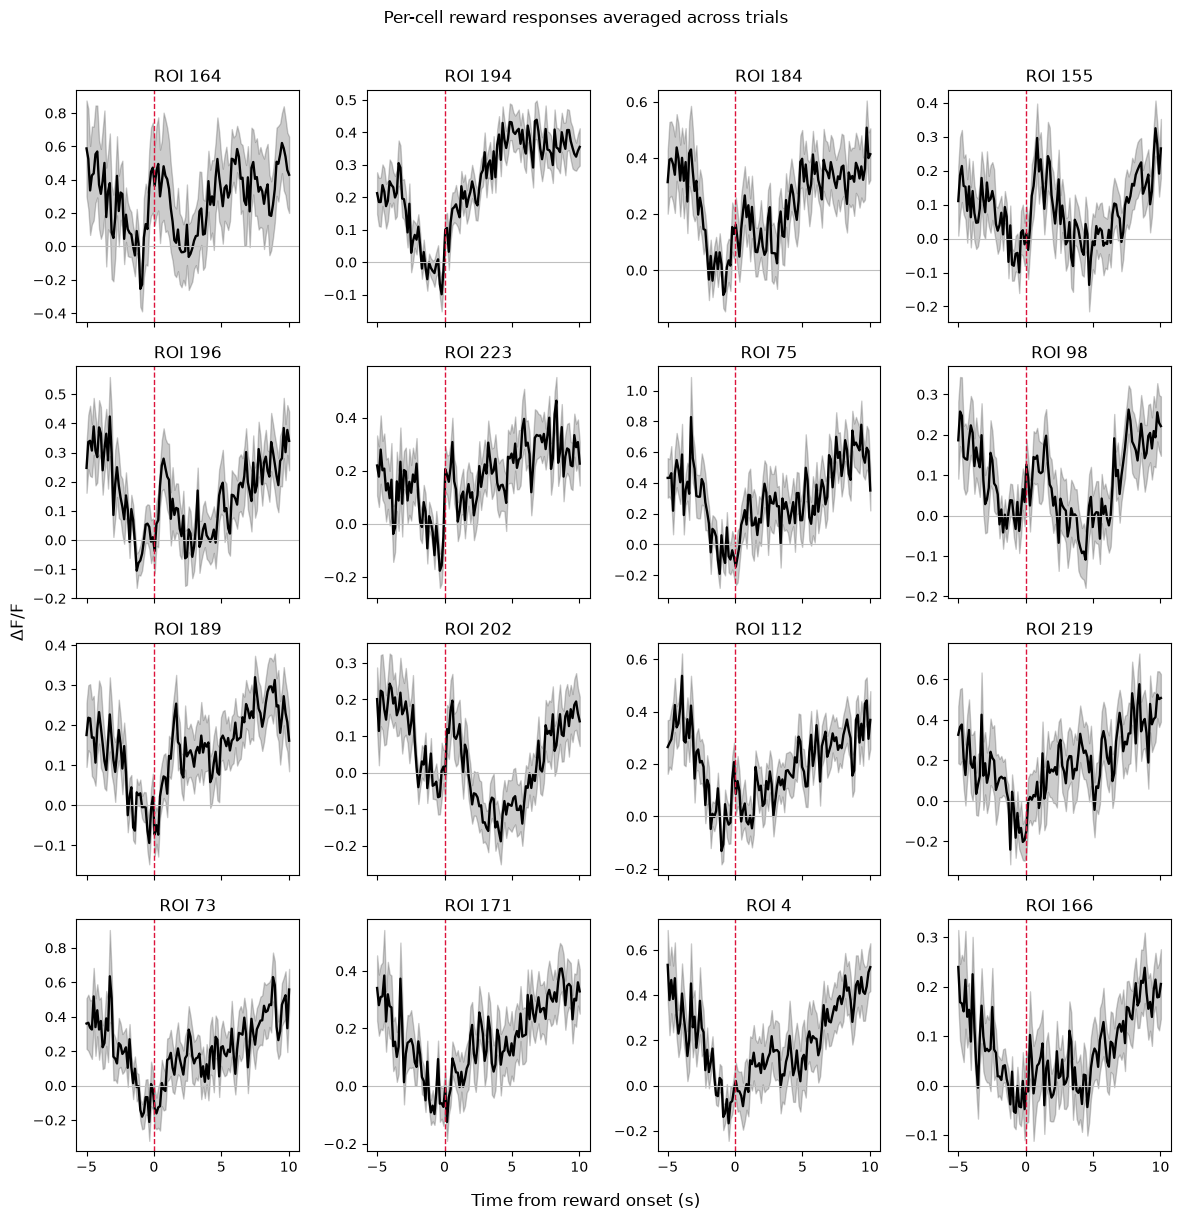

In [92]:
# Average across TRIALS only. Shapes remain ROIs × time.
roi_trial_mean = np.full((dff.shape[0], peri_reward.shape[2]), np.nan)
roi_trial_mean[valid_roi_indices] = np.nanmean(peri_reward[:, valid_roi_indices, :], axis=0)
n_trials_per_sample = np.sum(np.isfinite(peri_reward), axis=0)
roi_trial_sem = np.full_like(roi_trial_mean, np.nan)
roi_trial_sem[valid_roi_indices] = (
    np.nanstd(peri_reward[:, valid_roi_indices, :], axis=0, ddof=1)
    / np.sqrt(np.maximum(n_trials_per_sample[valid_roi_indices], 1))
)

response_mask = (relative_time >= 0) & (relative_time <= 2)
roi_response = np.nanmean(roi_trial_mean[:, response_mask], axis=1)
roi_order = valid_roi_indices[np.argsort(roi_response[valid_roi_indices])[::-1]]
N_ROIS_TO_PLOT = min(16, len(valid_roi_indices))
ROIS_TO_PLOT = roi_order[:N_ROIS_TO_PLOT]  # replace with explicit ROI indices if preferred

ncols = 4
nrows = int(np.ceil(len(ROIS_TO_PLOT) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3 * nrows), sharex=True, squeeze=False)
for ax, roi in zip(axes.flat, ROIS_TO_PLOT):
    mean = roi_trial_mean[roi]
    sem = roi_trial_sem[roi]
    ax.plot(relative_time, mean, color='black', lw=1.7)
    ax.fill_between(relative_time, mean - sem, mean + sem, color='black', alpha=.2)
    ax.axvline(0, color='crimson', ls='--', lw=1)
    ax.axhline(0, color='0.75', lw=.8)
    # Let each aligned mean determine its own y limits.  The 1st–99th
    # percentiles of the full recording are much wider than a trial average
    # and can make genuine reward-locked calcium kernels look flat.
    ax.set_title(f'ROI {roi}')
for ax in axes.flat[len(ROIS_TO_PLOT):]:
    ax.set_visible(False)
fig.supxlabel('Time from reward onset (s)')
fig.supylabel('ΔF/F')
fig.suptitle('Per-cell reward responses averaged across trials', y=1.01)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'peri_reward_per_cell_mean_sem.png', dpi=200, bbox_inches='tight')
plt.show()

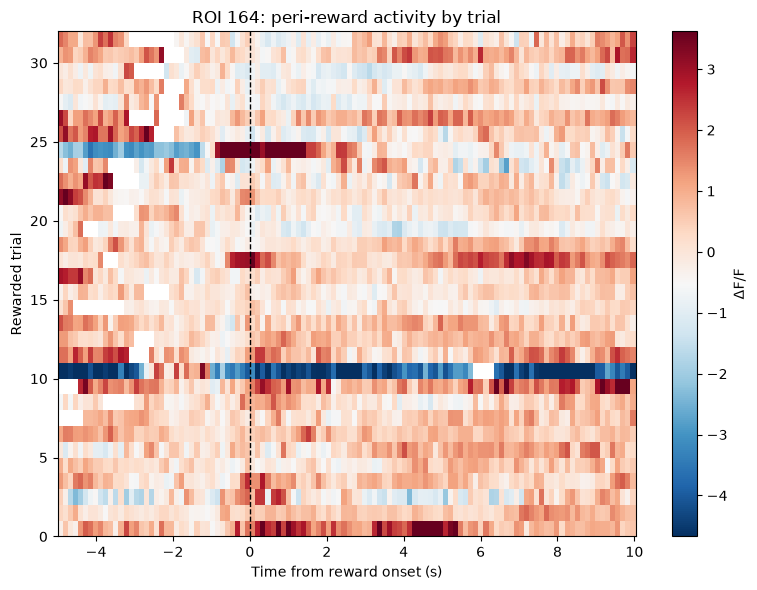

In [87]:
# Trial-by-trial heatmap for one cell; no averaging across cells.
EXAMPLE_ROI = int(ROIS_TO_PLOT[0])
example_trials = peri_reward[:, EXAMPLE_ROI, :]
fig, ax = plt.subplots(figsize=(8, 6))
vmin, vmax = np.nanpercentile(example_trials, TRACE_DISPLAY_PERCENTILES)
im = ax.imshow(
    example_trials, aspect='auto', origin='lower',
    extent=[relative_time[0], relative_time[-1], 0, len(example_trials)],
    cmap='RdBu_r', vmin=vmin, vmax=vmax
)
ax.axvline(0, color='black', ls='--', lw=1)
ax.set(xlabel='Time from reward onset (s)', ylabel='Rewarded trial', title=f'ROI {EXAMPLE_ROI}: peri-reward activity by trial')
fig.colorbar(im, ax=ax, label='ΔF/F')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / f'peri_reward_roi_{EXAMPLE_ROI}_trial_heatmap.png', dpi=200)
plt.show()

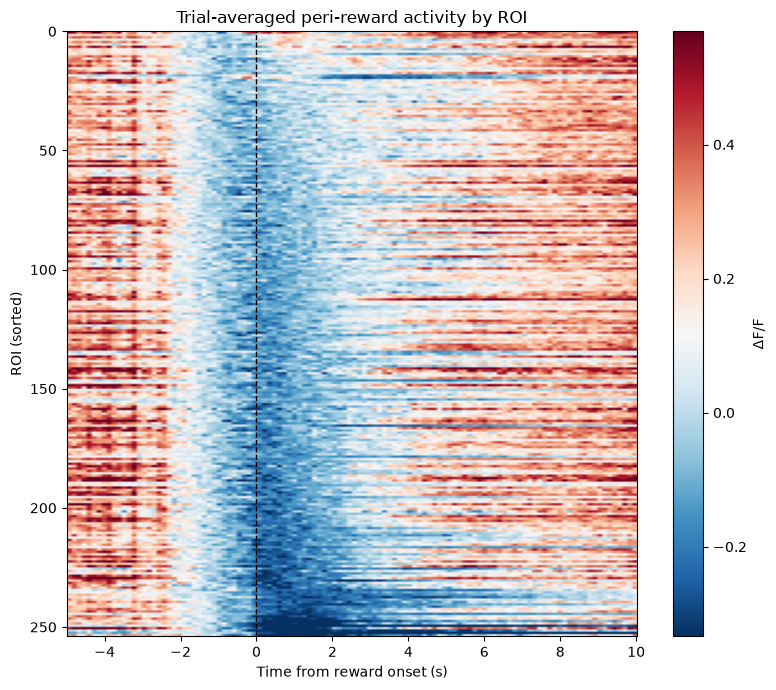

In [88]:
# Average each ROI across trials, sort by its 0–2 s response, and plot a heatmap.
sorted_roi_mean = roi_trial_mean[roi_order]
vmin, vmax = np.nanpercentile(sorted_roi_mean, TRACE_DISPLAY_PERCENTILES)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(
    sorted_roi_mean, aspect='auto', origin='upper',
    extent=[relative_time[0], relative_time[-1], len(roi_order), 0],
    cmap='RdBu_r', vmin=vmin, vmax=vmax
)
ax.axvline(0, color='black', ls='--', lw=1)
ax.set(xlabel='Time from reward onset (s)', ylabel='ROI (sorted)', title='Trial-averaged peri-reward activity by ROI')
fig.colorbar(im, ax=ax, label='ΔF/F')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'peri_reward_roi_heatmap.png', dpi=200)
plt.show()

## 6. Compare responses by delivered reward magnitude

Requested 21 cells total; plotting 21.
Top cells by delivered reward pulses:
  1 pulse(s): 6 exclusive cells — [164, 116, 211, 13, 14, 74]
  2 pulse(s): 5 exclusive cells — [132, 126, 58, 79, 125]
  3 pulse(s): 5 exclusive cells — [45, 109, 168, 12, 67]
  4 pulse(s): 5 exclusive cells — [227, 243, 32, 244, 221]


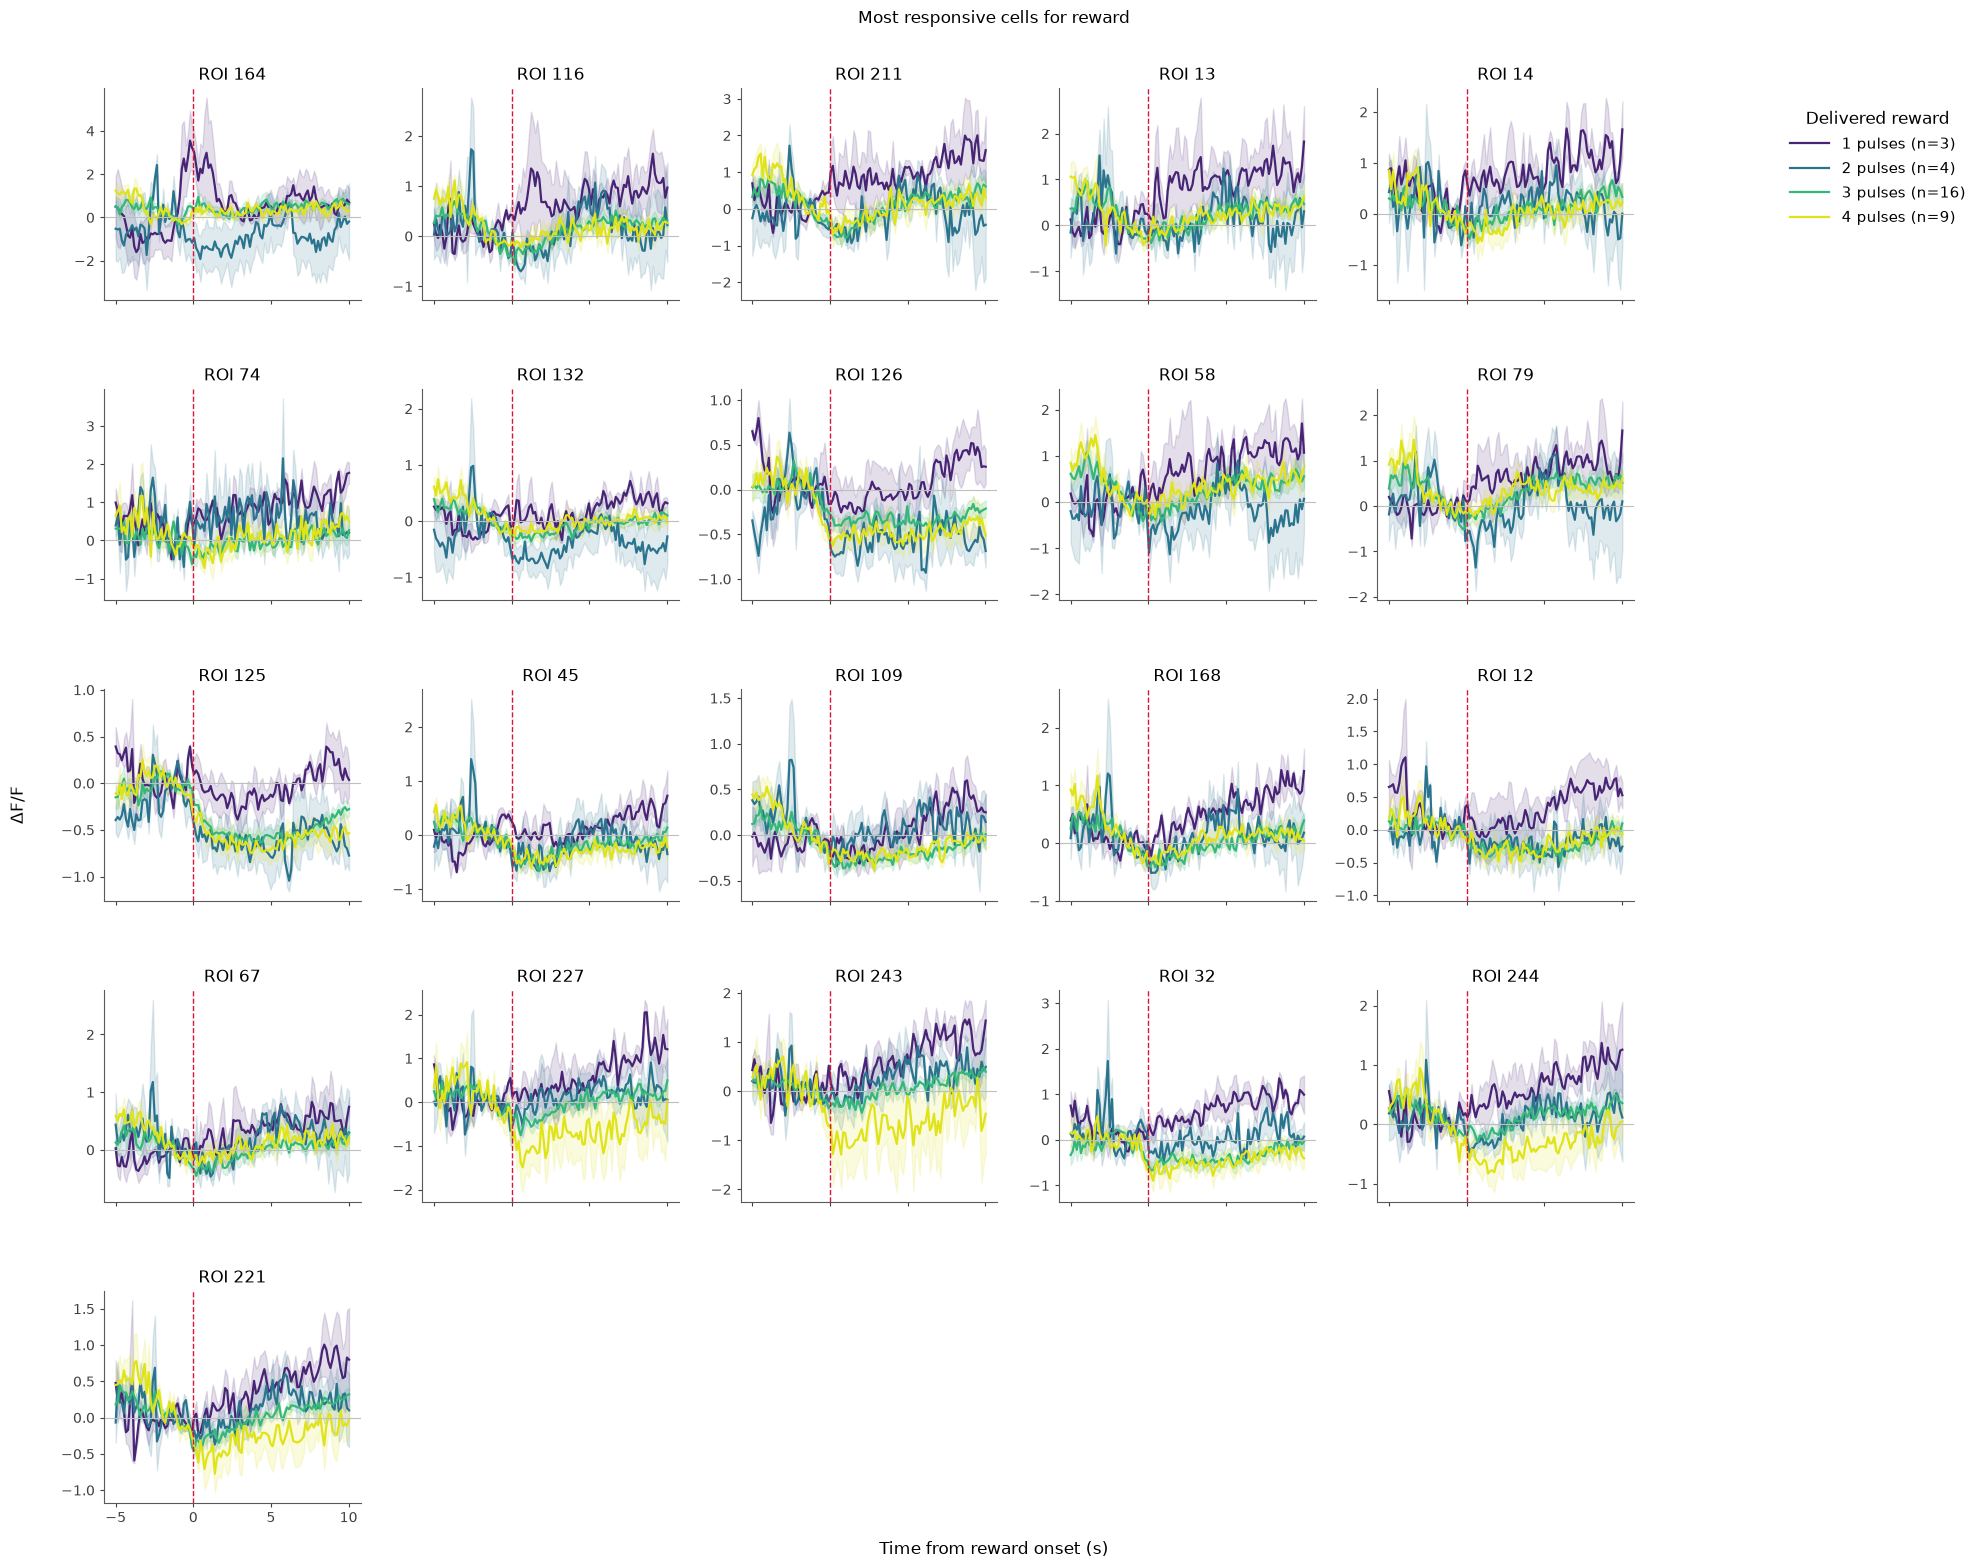

"\n# Response-amplitude matrix preserves exclusive category grouping.\nselected_response = magnitude_response[MAGNITUDE_ROIS]\nfig, ax = plt.subplots(figsize=(6, max(4, .45 * len(MAGNITUDE_ROIS))))\nvmin, vmax = np.nanpercentile(selected_response, TRACE_DISPLAY_PERCENTILES)\nim = ax.imshow(selected_response, aspect='auto', cmap='viridis', vmin=vmin, vmax=vmax)\nax.set_xticks(np.arange(len(magnitudes)), [f'{m:g}' for m in magnitudes])\nax.set_yticks(np.arange(len(MAGNITUDE_ROIS)), [f'ROI {r}' for r in MAGNITUDE_ROIS])\nboundary = 0\nfor magnitude in magnitudes[:-1]:\n    boundary += len(top_by_magnitude[int(magnitude)])\n    ax.axhline(boundary - 0.5, color='white', lw=1.5)\nax.set(xlabel='Delivered reward pulses', ylabel='Exclusively assigned cell', title='Post-reward response by exclusive peak category')\nfig.colorbar(im, ax=ax, label='Mean ΔF/F, 0–2 s')\nfig.tight_layout()\nfig.savefig(OUTPUT_DIR / 'reward_value_response_matrix.png', dpi=200, bbox_inches='tight')\nplt.show()\n"

In [89]:
# Rank cells separately by their 0–2 s response to each delivered value.
TARGET_MAGNITUDES = np.array([1., 2., 3., 4.])
TOTAL_CELLS_TO_PLOT = 21
magnitudes = TARGET_MAGNITUDES[np.isin(TARGET_MAGNITUDES, np.unique(reward_magnitudes))]
if len(magnitudes) == 0:
    raise ValueError('No 1–4 pulse rewarded trials were found.')

magnitude_response = np.full((dff.shape[0], len(magnitudes)), np.nan)
for mag_i, magnitude in enumerate(magnitudes):
    use = reward_magnitudes == magnitude
    magnitude_response[valid_roi_indices, mag_i] = np.nanmean(
        peri_reward[use][:, valid_roi_indices, :][:, :, response_mask], axis=(0, 2)
    )

# Exclusive assignment: each ROI belongs to the magnitude at which its
# absolute response amplitude is largest (captures activation or inhibition).
finite_score = np.where(np.isfinite(magnitude_response), np.abs(magnitude_response), -np.inf)
preferred_magnitude_index = np.argmax(finite_score, axis=1)
has_response = np.any(np.isfinite(magnitude_response), axis=1)
# Divide the requested total as evenly as possible across the available
# reward magnitudes. Any remainder is assigned to the first magnitudes.
base_per_magnitude, remainder = divmod(TOTAL_CELLS_TO_PLOT, len(magnitudes))
cells_requested = np.full(len(magnitudes), base_per_magnitude, dtype=int)
cells_requested[:remainder] += 1

top_by_magnitude = {}
selected = []
for mag_i, magnitude in enumerate(magnitudes):
    candidates = np.flatnonzero(has_response & (preferred_magnitude_index == mag_i))
    candidate_scores = np.abs(magnitude_response[candidates, mag_i])
    ranking = candidates[np.argsort(np.nan_to_num(candidate_scores, nan=-np.inf))[::-1]]
    top = ranking[:cells_requested[mag_i]]
    top_by_magnitude[int(magnitude)] = top
    selected.extend(top.tolist())
MAGNITUDE_ROIS = np.array(list(dict.fromkeys(selected)), dtype=int)
print(f'Requested {TOTAL_CELLS_TO_PLOT} cells total; plotting {len(MAGNITUDE_ROIS)}.')
print('Top cells by delivered reward pulses:')
for magnitude, cells in top_by_magnitude.items():
    print(f'  {magnitude} pulse(s): {len(cells)} exclusive cells — {cells.tolist()}')
if len(MAGNITUDE_ROIS) != len(np.unique(MAGNITUDE_ROIS)):
    raise RuntimeError('Exclusive magnitude selection produced duplicate ROI assignments.')

colors = plt.cm.viridis(np.linspace(.1, .95, len(magnitudes)))
ncols = 5
nrows = int(np.ceil(len(MAGNITUDE_ROIS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 3 * nrows), sharex=True, squeeze=False)
for ax, roi in zip(axes.flat, MAGNITUDE_ROIS):
    for color, magnitude in zip(colors, magnitudes):
        use = reward_magnitudes == magnitude
        traces = peri_reward[use, roi, :]
        mean = np.nanmean(traces, axis=0)
        sem = (np.nanstd(traces, axis=0, ddof=1) / np.sqrt(use.sum())) if use.sum() > 1 else np.zeros_like(mean)
        ax.plot(relative_time, mean, color=color, lw=1.6, label=f'{magnitude:g} pulses (n={use.sum()})')
        ax.fill_between(relative_time, mean - sem, mean + sem, color=color, alpha=.15)
    ax.axvline(0, color='crimson', ls='--', lw=1)
    ax.axhline(0, color='0.75', lw=.8)
    # Autoscale from these aligned magnitude means/SEMs, rather than from
    # the much wider distribution of the complete raw recording.
    preferred = magnitudes[preferred_magnitude_index[roi]]
    if len(magnitudes) > 1:
        slope = np.polyfit(magnitudes, magnitude_response[roi], 1)[0]
        ax.set_title(f'ROI {roi}')
    else:
        ax.set_title(f'ROI {roi}')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('0.35')
    ax.spines['bottom'].set_color('0.35')
    ax.tick_params(axis='both', direction='out', length=3, colors='0.25')
for ax in axes.flat[len(MAGNITUDE_ROIS):]:
    ax.set_visible(False)
legend_handles, legend_labels = axes.flat[0].get_legend_handles_labels()
legend = fig.legend(
    legend_handles,
    legend_labels,
    title='Delivered reward',
    fontsize=11,
    title_fontsize=12,
    frameon=True,
    framealpha=0.92,
    edgecolor='none',
    handlelength=2.6,
    handletextpad=0.8,
    labelspacing=0.6,
    borderpad=0.7,
    loc='upper right',
    bbox_to_anchor=(0.995, 0.975),
)
fig.supxlabel('Time from reward onset (s)', y=-0.002)
fig.supylabel('ΔF/F', x=0.008)
fig.suptitle('Most responsive cells for reward', y=1.03)
fig.subplots_adjust(left=0.055, right=0.82, bottom=0.035, top=0.978, hspace=0.42, wspace=0.24)
fig.savefig(OUTPUT_DIR / 'peri_reward_top_cells_by_magnitude.png', dpi=200, bbox_inches='tight')
plt.show()

"""
# Response-amplitude matrix preserves exclusive category grouping.
selected_response = magnitude_response[MAGNITUDE_ROIS]
fig, ax = plt.subplots(figsize=(6, max(4, .45 * len(MAGNITUDE_ROIS))))
vmin, vmax = np.nanpercentile(selected_response, TRACE_DISPLAY_PERCENTILES)
im = ax.imshow(selected_response, aspect='auto', cmap='viridis', vmin=vmin, vmax=vmax)
ax.set_xticks(np.arange(len(magnitudes)), [f'{m:g}' for m in magnitudes])
ax.set_yticks(np.arange(len(MAGNITUDE_ROIS)), [f'ROI {r}' for r in MAGNITUDE_ROIS])
boundary = 0
for magnitude in magnitudes[:-1]:
    boundary += len(top_by_magnitude[int(magnitude)])
    ax.axhline(boundary - 0.5, color='white', lw=1.5)
ax.set(xlabel='Delivered reward pulses', ylabel='Exclusively assigned cell', title='Post-reward response by exclusive peak category')
fig.colorbar(im, ax=ax, label='Mean ΔF/F, 0–2 s')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'reward_value_response_matrix.png', dpi=200, bbox_inches='tight')
plt.show()
"""

## Saved outputs

- `aligned_session.pkl`: canonical bandit behavior plus imaging clock alignment
- `img_session_data.pkl`: `dF`, aligned session, and frame rate
- `rsync_qc.png`: clock offset/drift and matching error
- population mean, trial heatmap, ROI heatmap, and magnitude-separated reward plots